# 5. Jensen's inequality and its consequences

**Cover and Thomas, Sections 2.6 and 2.7.**

This notebook collects the inequalities of the chapter and tests each one
numerically. The results tested here are:

| | statement |
|---|---|
| Thm 2.6.1 | $f'' \ge 0$ implies $f$ convex |
| Thm 2.6.2 | Jensen: $\mathbb E f(X) \ge f(\mathbb E X)$ for convex $f$ |
| Thm 2.6.3 | information inequality: $D(p\Vert q) \ge 0$, equality iff $p = q$ |
| | corollaries: $I(X;Y) \ge 0$, $I(X;Y\mid Z) \ge 0$ |
| Thm 2.6.4 | $H(X) \le \log \lvert \mathcal X \rvert$, equality iff uniform |
| Thm 2.6.5 | conditioning reduces entropy: $H(X \mid Y) \le H(X)$ |
| Thm 2.6.6 | independence bound: $H(X_1,\dots,X_n) \le \sum_i H(X_i)$ |
| Thm 2.7.1 | log sum inequality |
| Thm 2.7.2 | $D(p\Vert q)$ is convex in the pair $(p,q)$ |
| Thm 2.7.3 | $H(p)$ is concave in $p$ |
| Thm 2.7.4 | $I(X;Y)$ is concave in $p(x)$, convex in $p(y\mid x)$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(5)

## 5.1 Convex functions and Jensen's inequality

$f$ is **convex** on $(a,b)$ if for all $x_1, x_2$ in the interval and all
$0 \le \lambda \le 1$,

$$f(\lambda x_1 + (1-\lambda)x_2) \le \lambda f(x_1) + (1-\lambda) f(x_2),$$

that is, the function lies below every chord. **Theorem 2.6.1** says that a
non-negative second derivative is enough.

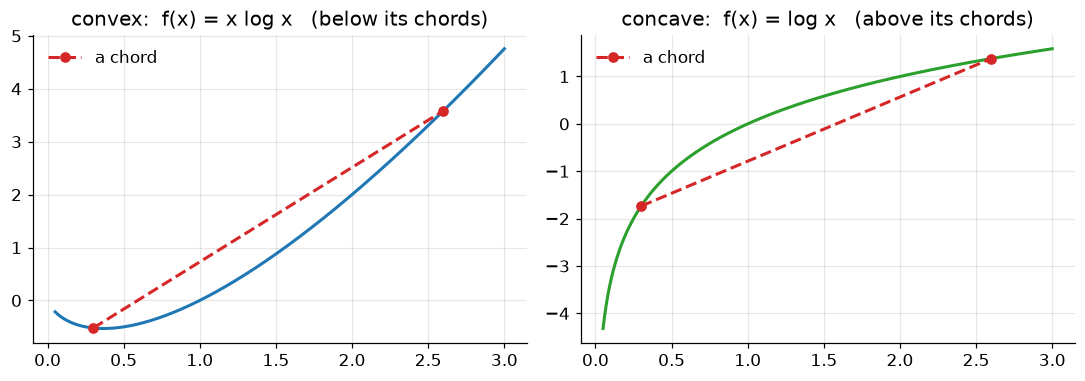

In [2]:
x = np.linspace(0.05, 3.0, 300)
x1, x2 = 0.3, 2.6
lam = np.linspace(0, 1, 50)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].plot(x, x * np.log2(x), color=it.COLORS["H"])
axes[0].plot([x1, x2], [x1*np.log2(x1), x2*np.log2(x2)], "o--",
             color=it.COLORS["D"], label="a chord")
axes[0].set_title("convex:  f(x) = x log x   (below its chords)")
axes[0].legend()

axes[1].plot(x, np.log2(x), color=it.COLORS["I"])
axes[1].plot([x1, x2], [np.log2(x1), np.log2(x2)], "o--",
             color=it.COLORS["D"], label="a chord")
axes[1].set_title("concave:  f(x) = log x   (above its chords)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Theorem 2.6.2 (Jensen).** If $f$ is convex and $X$ is a random variable,
then $\mathbb E f(X) \ge f(\mathbb E X)$.

E[X]     = 0.930000
f(E[X])  = -0.097369
E[f(X)]  = 0.364613
[PASS] Jensen: E f(X) >= f(E X)


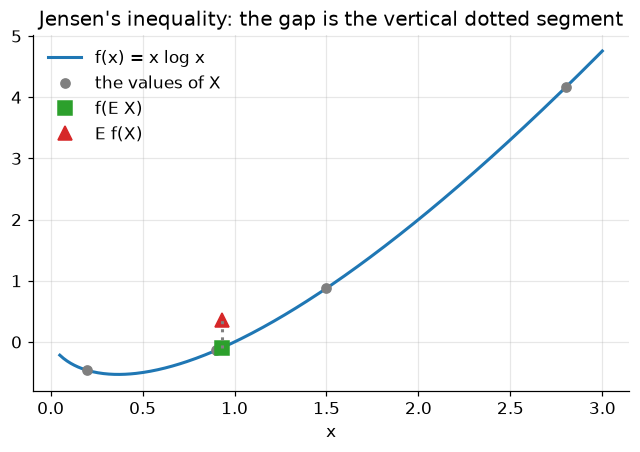

In [3]:
values = np.array([0.2, 0.9, 1.5, 2.8])      # <-- values that X can take
p = np.array([0.4, 0.3, 0.2, 0.1])           # <-- their probabilities

f = lambda t: t * np.log2(t)                 # a convex function

EX = float(np.sum(p * values))
Ef = float(np.sum(p * f(values)))

print(f"E[X]     = {EX:.6f}")
print(f"f(E[X])  = {f(EX):.6f}")
print(f"E[f(X)]  = {Ef:.6f}")
it.check("Jensen: E f(X) >= f(E X)", Ef >= f(EX) - 1e-12)

plt.plot(x, f(x), color=it.COLORS["H"], label="f(x) = x log x")
plt.plot(values, f(values), "o", color=it.COLORS["bound"], label="the values of X")
plt.plot([EX], [f(EX)], "s", color=it.COLORS["I"], markersize=9, label="f(E X)")
plt.plot([EX], [Ef], "^", color=it.COLORS["D"], markersize=9, label="E f(X)")
plt.vlines(EX, f(EX), Ef, color=it.COLORS["bound"], linestyles="dotted")
plt.xlabel("x")
plt.legend()
plt.title("Jensen's inequality: the gap is the vertical dotted segment")
plt.show()

## 5.2 Theorem 2.6.3: the information inequality

$$D(p\,\Vert \,q) \ge 0, \qquad \text{with equality if and only if } p = q.$$

Everything else in this notebook follows from this one statement.

In [4]:
n_tests = 20_000
smallest = np.inf
for _ in range(n_tests):
    k = int(rng.integers(2, 9))
    a = it.random_pmf(k, rng)
    b = it.random_pmf(k, rng)
    smallest = min(smallest, it.relative_entropy(a, b))

it.check(f"D(p||q) >= 0 on {n_tests} random pairs", smallest >= 0,
         f"smallest value seen: {smallest:.3e}")
it.check("D(p||p) = 0 exactly", it.relative_entropy(a, a) == 0.0)

# how close to zero does D get when q approaches p?
p0 = it.random_pmf(4, rng)
for t in [0.5, 0.1, 0.01, 0.001]:
    q0 = (1 - t) * p0 + t * it.random_pmf(4, rng)
    print(f"q at distance t = {t:<6}:  D(p||q) = {it.relative_entropy(p0, q0):.3e}")

[PASS] D(p||q) >= 0 on 20000 random pairs   smallest value seen: 1.777e-06
[PASS] D(p||p) = 0 exactly
q at distance t = 0.5   :  D(p||q) = 1.495e-01
q at distance t = 0.1   :  D(p||q) = 2.097e-03
q at distance t = 0.01  :  D(p||q) = 1.824e-05
q at distance t = 0.001 :  D(p||q) = 2.523e-07


**Corollaries.** $I(X;Y) = D\big(p(x,y)\Vert p(x)p(y)\big) \ge 0$, with equality
exactly when $X$ and $Y$ are independent; and $I(X;Y\mid Z) \ge 0$.

In [5]:
worst_I, worst_Ic = np.inf, np.inf
for _ in range(5000):
    Q = it.random_joint(int(rng.integers(2, 5)), int(rng.integers(2, 5)), rng)
    worst_I = min(worst_I, it.mutual_information(Q))
    Q3 = rng.dirichlet(np.ones(2 * 3 * 2)).reshape(2, 3, 2)
    worst_Ic = min(worst_Ic, it.cond_mutual_information(Q3))

it.check("I(X;Y) >= 0", worst_I >= 0, f"smallest: {worst_I:.3e}")
it.check("I(X;Y|Z) >= 0", worst_Ic >= 0, f"smallest: {worst_Ic:.3e}")

independent = np.outer(it.random_pmf(3, rng), it.random_pmf(4, rng))
it.check("I(X;Y) = 0 for an independent pair",
         abs(it.mutual_information(independent)) < 1e-12)

[PASS] I(X;Y) >= 0   smallest: 3.638e-06
[PASS] I(X;Y|Z) >= 0   smallest: 1.059e-03
[PASS] I(X;Y) = 0 for an independent pair


True

## 5.3 Theorem 2.6.4: $H(X) \le \log \lvert \mathcal X \rvert$

The proof is one line once you notice that, for the uniform distribution $u$,

$$D(p \,\Vert \, u) = \sum_x p(x) \log \frac{p(x)}{1/|\mathcal X|}
= \log |\mathcal X| - H(p) \; \ge \; 0 .$$

In [6]:
m = 5
u = np.ones(m) / m

for _ in range(3):
    p = it.random_pmf(m, rng)
    D = it.relative_entropy(p, u)
    print(f"H(p) = {it.entropy(p):.6f},  D(p||u) = {D:.6f},  "
          f"H(p) + D(p||u) = {it.entropy(p) + D:.6f}   (log2 {m} = {np.log2(m):.6f})")

worst = -np.inf
for _ in range(20_000):
    worst = max(worst, it.entropy(it.random_pmf(m, rng)))
it.check(f"H <= log2({m}) on 20000 random distributions", worst <= np.log2(m) + 1e-12,
         f"largest seen: {worst:.6f}")
it.check("equality for the uniform distribution", np.isclose(it.entropy(u), np.log2(m)))

H(p) = 2.115721,  D(p||u) = 0.206208,  H(p) + D(p||u) = 2.321928   (log2 5 = 2.321928)
H(p) = 2.089808,  D(p||u) = 0.232120,  H(p) + D(p||u) = 2.321928   (log2 5 = 2.321928)
H(p) = 1.741353,  D(p||u) = 0.580575,  H(p) + D(p||u) = 2.321928   (log2 5 = 2.321928)
[PASS] H <= log2(5) on 20000 random distributions   largest seen: 2.316244
[PASS] equality for the uniform distribution


True

## 5.4 Theorem 2.6.5: conditioning reduces entropy

$$H(X \mid Y) \le H(X), \qquad \text{equality iff } X \perp Y,$$

because $H(X) - H(X\mid Y) = I(X;Y) \ge 0$.

**This is true only on the average.** Example 2.6.1 of the book makes the
point: the joint distribution

$$
\begin{array}{c|cc}
 & y=1 & y=2 \\ \hline
x=1 & 0 & 1/8 \\
x=2 & 3/4 & 1/8
\end{array}
$$

has $H(X) = H(\tfrac18, \tfrac78) = 0.544$ bit, $H(X\mid Y=1) = 0$ bits and
$H(X \mid Y = 2) = 1$ bit. Observing $Y = 2$ *increases* the uncertainty about
$X$, yet the average $H(X\mid Y) = \tfrac34 \cdot 0 + \tfrac14 \cdot 1 = 0.25$
bit is smaller than $H(X)$.

In [7]:
P = np.array([[0.0,  1/8],
              [3/4,  1/8]])
it.show_table(P)
print()

pY = it.marginal_Y(P)
H_X = it.entropy(it.marginal_X(P))
print(f"H(X)       = {H_X:.4f}   book: 0.544")
for j in range(2):
    h = it.entropy(P[:, j] / pY[j])
    print(f"H(X|Y={j+1})  = {h:.4f}     p(Y={j+1}) = {pY[j]:.4f}")
print(f"H(X|Y)     = {it.cond_entropy_X_given_Y(P):.4f}   book: 0.25")

it.check("H(X|Y=2) > H(X): a single observation can increase uncertainty",
         it.entropy(P[:, 1] / pY[1]) > H_X)
it.check("H(X|Y) <= H(X): on the average it cannot",
         it.cond_entropy_X_given_Y(P) <= H_X)

X\Y           1        2       p(x)
    1    0.0000   0.1250     0.1250
    2    0.7500   0.1250     0.8750
 p(y)    0.7500   0.2500     1.0000

H(X)       = 0.5436   book: 0.544
H(X|Y=1)  = 0.0000     p(Y=1) = 0.7500
H(X|Y=2)  = 1.0000     p(Y=2) = 0.2500
H(X|Y)     = 0.2500   book: 0.25
[PASS] H(X|Y=2) > H(X): a single observation can increase uncertainty
[PASS] H(X|Y) <= H(X): on the average it cannot


True

In [8]:
worst_gap = np.inf
for _ in range(10_000):
    Q = it.random_joint(int(rng.integers(2, 6)), int(rng.integers(2, 6)), rng)
    gap = it.entropy(it.marginal_X(Q)) - it.cond_entropy_X_given_Y(Q)
    worst_gap = min(worst_gap, gap)

it.check("H(X|Y) <= H(X) on 10000 random joint distributions", worst_gap >= -1e-12,
         f"smallest H(X) - H(X|Y) seen: {worst_gap:.3e}")

[PASS] H(X|Y) <= H(X) on 10000 random joint distributions   smallest H(X) - H(X|Y) seen: 4.928e-09


True

## 5.5 Theorem 2.6.6: the independence bound

$$H(X_1, \dots, X_n) \le \sum_{i=1}^n H(X_i),$$

with equality exactly when the variables are independent. It follows from the
chain rule together with Theorem 2.6.5.

In [9]:
worst = np.inf
for _ in range(3000):
    sizes = (int(rng.integers(2, 4)), int(rng.integers(2, 4)), int(rng.integers(2, 4)))
    Q = rng.dirichlet(np.ones(int(np.prod(sizes)))).reshape(sizes)
    sum_marginals = (it.entropy(Q.sum(axis=(1, 2))) + it.entropy(Q.sum(axis=(0, 2)))
                     + it.entropy(Q.sum(axis=(0, 1))))
    worst = min(worst, sum_marginals - it.entropy(Q))

it.check("H(X1,X2,X3) <= H(X1) + H(X2) + H(X3)", worst >= -1e-12,
         f"smallest slack seen: {worst:.3e}")

# equality for an independent triple
a, b, c = it.random_pmf(3, rng), it.random_pmf(2, rng), it.random_pmf(4, rng)
Q = a[:, None, None] * b[None, :, None] * c[None, None, :]
it.check("equality when the three variables are independent",
         np.isclose(it.entropy(Q), it.entropy(a) + it.entropy(b) + it.entropy(c)))

[PASS] H(X1,X2,X3) <= H(X1) + H(X2) + H(X3)   smallest slack seen: 1.285e-02
[PASS] equality when the three variables are independent


True

## 5.6 Theorem 2.7.1: the log sum inequality

For non-negative numbers $a_1,\dots,a_n$ and $b_1,\dots,b_n$,

$$\sum_i a_i \log \frac{a_i}{b_i} \;\ge\; \left(\sum_i a_i\right)
\log \frac{\sum_i a_i}{\sum_i b_i},$$

with equality if and only if $a_i / b_i$ is constant.

In [10]:
def log_sum_left(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    nz = a > 0
    return float(np.sum(a[nz] * np.log2(a[nz] / b[nz])))


def log_sum_right(a, b):
    A, B = float(np.sum(a)), float(np.sum(b))
    return A * np.log2(A / B) if A > 0 else 0.0


worst = np.inf
for _ in range(20_000):
    k = int(rng.integers(2, 8))
    a = rng.random(k) * 3
    b = rng.random(k) * 3
    worst = min(worst, log_sum_left(a, b) - log_sum_right(a, b))

it.check("log sum inequality on 20000 random pairs of vectors", worst >= -1e-12,
         f"smallest slack seen: {worst:.3e}")

a = np.array([1.0, 2.0, 3.0])
it.check("equality when a_i / b_i is constant",
         np.isclose(log_sum_left(a, 2 * a), log_sum_right(a, 2 * a)))

[PASS] log sum inequality on 20000 random pairs of vectors   smallest slack seen: 6.947e-07
[PASS] equality when a_i / b_i is constant


True

## 5.7 Theorem 2.7.2: $D(p\Vert q)$ is convex in the pair $(p,q)$

$$D(\lambda p_1 + (1-\lambda)p_2 \,\Vert \, \lambda q_1 + (1-\lambda)q_2)
\;\le\; \lambda D(p_1\Vert q_1) + (1-\lambda) D(p_2\Vert q_2).$$

We plot both sides as functions of $\lambda$.

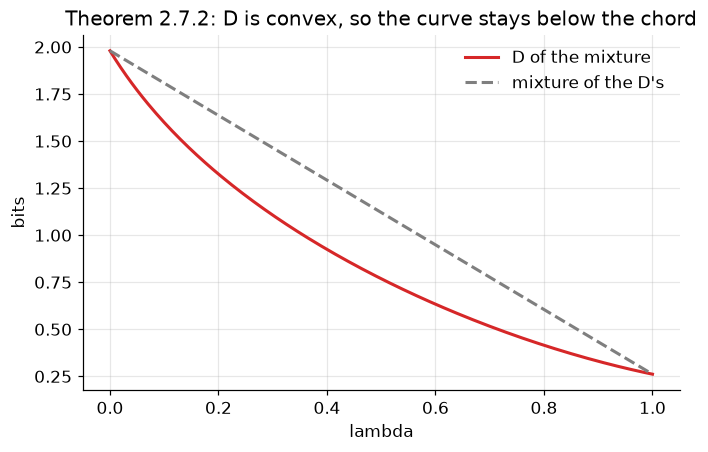

[PASS] D of the mixture <= mixture of the D's


True

In [11]:
p1, q1 = it.random_pmf(4, rng), it.random_pmf(4, rng)
p2, q2 = it.random_pmf(4, rng), it.random_pmf(4, rng)
lams = np.linspace(0, 1, 201)

curve = [it.relative_entropy(l*p1 + (1-l)*p2, l*q1 + (1-l)*q2) for l in lams]
chord = [l*it.relative_entropy(p1, q1) + (1-l)*it.relative_entropy(p2, q2) for l in lams]

plt.plot(lams, curve, color=it.COLORS["D"], label="D of the mixture")
plt.plot(lams, chord, "--", color=it.COLORS["bound"], label="mixture of the D's")
plt.xlabel("lambda")
plt.ylabel("bits")
plt.title("Theorem 2.7.2: D is convex, so the curve stays below the chord")
plt.legend()
plt.show()

it.check("D of the mixture <= mixture of the D's",
         all(c <= d + 1e-12 for c, d in zip(curve, chord)))

## 5.8 Theorem 2.7.3: $H(p)$ is concave in $p$

From $H(p) = \log|\mathcal X| - D(p\Vert u)$ and the convexity of $D$.
Two pictures: a section along a segment, and the whole simplex for three
outcomes.

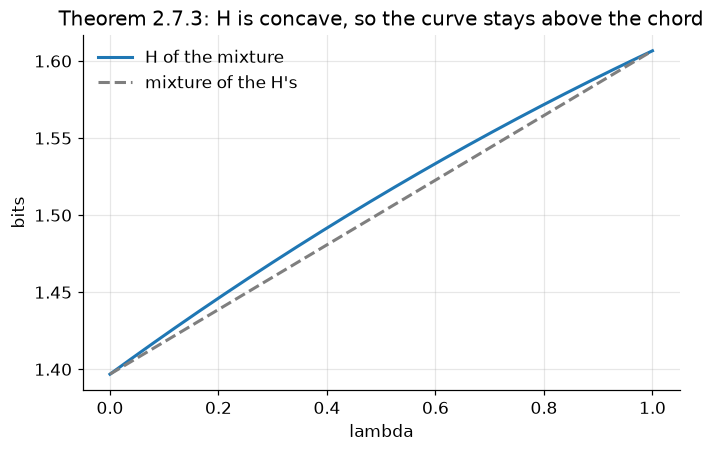

[PASS] H of the mixture >= mixture of the H's


True

In [12]:
pA, pB = it.random_pmf(4, rng), it.random_pmf(4, rng)
curve = [it.entropy(l*pA + (1-l)*pB) for l in lams]
chord = [l*it.entropy(pA) + (1-l)*it.entropy(pB) for l in lams]

plt.plot(lams, curve, color=it.COLORS["H"], label="H of the mixture")
plt.plot(lams, chord, "--", color=it.COLORS["bound"], label="mixture of the H's")
plt.xlabel("lambda")
plt.ylabel("bits")
plt.title("Theorem 2.7.3: H is concave, so the curve stays above the chord")
plt.legend()
plt.show()

it.check("H of the mixture >= mixture of the H's",
         all(c >= d - 1e-12 for c, d in zip(curve, chord)))

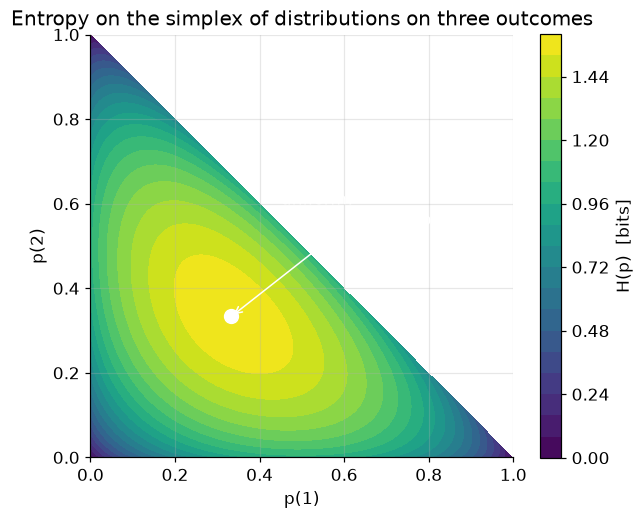

In [13]:
# Entropy over the whole simplex of distributions on three outcomes.
grid = 300
p1_axis = np.linspace(0, 1, grid)
p2_axis = np.linspace(0, 1, grid)
G1, G2 = np.meshgrid(p1_axis, p2_axis)
G3 = 1 - G1 - G2

terms = np.zeros_like(G1)
for arr in (G1, G2, G3):
    safe = np.where(arr > 0, arr, 1.0)     # avoid log(0); those terms are 0 anyway
    terms += np.where(arr > 0, -safe * np.log2(safe), 0.0)

inside = G3 >= 0                           # the simplex is the lower triangle
H_surface = np.where(inside, terms, np.nan)

plt.figure(figsize=(6.2, 5.0))
plt.contourf(G1, G2, H_surface, levels=25, cmap="viridis")
plt.colorbar(label="H(p)  [bits]")
plt.plot([1/3], [1/3], "o", color="white", markersize=9)
plt.annotate("uniform:\nlog2(3) = 1.585 bits", xy=(1/3, 1/3), xytext=(0.45, 0.55),
             color="white", arrowprops=dict(arrowstyle="->", color="white"))
plt.xlabel("p(1)")
plt.ylabel("p(2)")
plt.title("Entropy on the simplex of distributions on three outcomes")
plt.gca().set_aspect("equal")
plt.show()

The level curves are closed and nested around the uniform distribution, which
is what concavity with a single interior maximum looks like.

## 5.9 Theorem 2.7.4: how $I(X;Y)$ depends on its two arguments

With $p(x,y) = p(x)\,p(y\mid x)$:

* for fixed $p(y\mid x)$, $I(X;Y)$ is **concave** in $p(x)$;
* for fixed $p(x)$, $I(X;Y)$ is **convex** in $p(y \mid x)$.

Both are illustrated on the binary symmetric channel.

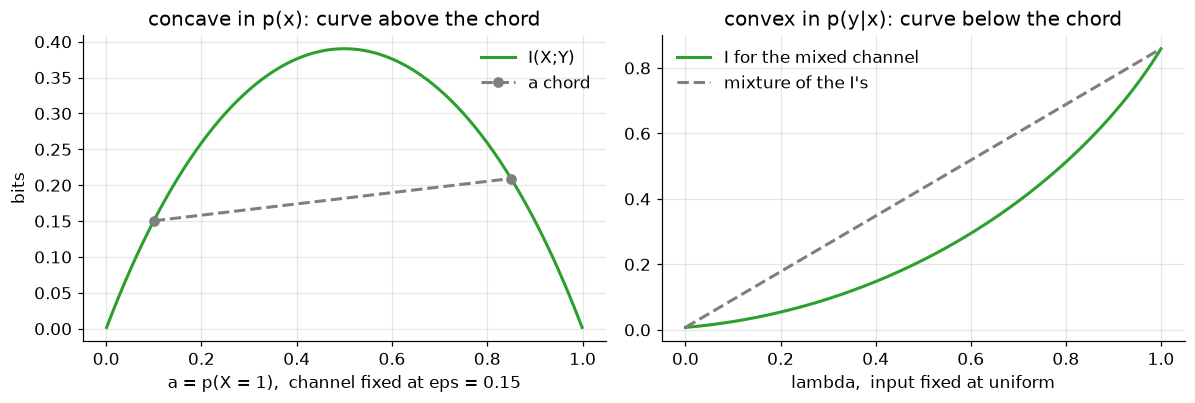

[PASS] I is concave in p(x) along this chord
[PASS] I is convex in p(y|x) along this chord


True

In [14]:
def joint_from(pX, channel):
    return np.asarray(pX, float)[:, None] * np.asarray(channel, float)


def bsc(eps):
    return np.array([[1 - eps, eps], [eps, 1 - eps]])


# (a) concave in p(x): fix the channel, move the input distribution
channel = bsc(0.15)
a_grid = np.linspace(0.001, 0.999, 400)
I_of_a = [it.mutual_information(joint_from([1 - a, a], channel)) for a in a_grid]

# a chord between two input distributions
a1, a2 = 0.1, 0.85
I1 = it.mutual_information(joint_from([1 - a1, a1], channel))
I2 = it.mutual_information(joint_from([1 - a2, a2], channel))

# (b) convex in p(y|x): fix the input, mix two channels
pX = [0.5, 0.5]
W1, W2 = bsc(0.02), bsc(0.45)
I_mix = [it.mutual_information(joint_from(pX, l*W1 + (1-l)*W2)) for l in lams]
I_chord = [l*it.mutual_information(joint_from(pX, W1))
           + (1-l)*it.mutual_information(joint_from(pX, W2)) for l in lams]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(a_grid, I_of_a, color=it.COLORS["I"], label="I(X;Y)")
axes[0].plot([a1, a2], [I1, I2], "o--", color=it.COLORS["bound"], label="a chord")
axes[0].set_xlabel("a = p(X = 1),  channel fixed at eps = 0.15")
axes[0].set_ylabel("bits")
axes[0].set_title("concave in p(x): curve above the chord")
axes[0].legend()

axes[1].plot(lams, I_mix, color=it.COLORS["I"], label="I for the mixed channel")
axes[1].plot(lams, I_chord, "--", color=it.COLORS["bound"], label="mixture of the I's")
axes[1].set_xlabel("lambda,  input fixed at uniform")
axes[1].set_title("convex in p(y|x): curve below the chord")
axes[1].legend()
plt.tight_layout()
plt.show()

def I_at(a):
    return it.mutual_information(joint_from([1 - a, a], channel))


it.check("I is concave in p(x) along this chord",
         all(I_at(l*a1 + (1-l)*a2) >= l*I1 + (1-l)*I2 - 1e-12 for l in lams))
it.check("I is convex in p(y|x) along this chord",
         all(m <= c + 1e-12 for m, c in zip(I_mix, I_chord)))

## Things to try

1. In Section 5.1, replace $f(x) = x \log x$ by $f(x) = e^x$ and by
   $f(x) = \sqrt x$. Which way does Jensen's inequality point in each case?
2. Verify the equality condition in Theorem 2.6.5: build a joint distribution
   in which $X$ and $Y$ are independent and check that $H(X\mid Y) = H(X)$
   exactly.
3. For the simplex picture in Section 5.8, plot $D(p \Vert q)$ as a function of
   $p$ for a fixed $q$. Where is the minimum, and what do the level curves
   look like near it?
4. In Section 5.9, the maximum of the concave curve is the **capacity** of
   the channel. Find it numerically for a channel that is *not* symmetric,
   for example `np.array([[0.9, 0.1], [0.3, 0.7]])`. Is the maximising input
   still uniform?